In [ ]:
import os
import logging
from google.colab import drive

# 1. Configure logging
logging.basicConfig(level=logging.INFO, format="%(asctime)s [%(levelname)s] %(message)s", force=True)
logger = logging.getLogger(__name__)

# 2. Mount Google Drive
drive.mount('/content/drive')

# 3.  INPUT Directory
INPUT_DIR = "/content/drive/MyDrive/frugalAi"
IMAGES_DIR = os.path.join(INPUT_DIR, "generated_portraits_hashed")
CSV_PATH = os.path.join(INPUT_DIR, "sampled_dataset.csv")

if not os.path.exists(CSV_PATH):
    raise FileNotFoundError(f"Could not find CSV at {CSV_PATH}")
assert os.path.exists(IMAGES_DIR), f"Images directory is missing at {IMAGES_DIR}!"

logger.info(f"Using CSV from: {CSV_PATH}")
logger.info(f"Looking for images in: {IMAGES_DIR}")

# 4.  OUTPUT Directory
OUTPUT_BASE_DIR = "/content/drive/MyDrive/Frugal AI Project"

if not os.path.exists(OUTPUT_BASE_DIR):
    raise FileNotFoundError(f"Cannot find {OUTPUT_BASE_DIR}. Ensure you added a shortcut to it in your 'My Drive'!")

# 5.  Output Paths for GLASSES
ACCESSORY_TYPE = "glasses"
OUTPUT_IMAGES_DIR = os.path.join(OUTPUT_BASE_DIR, f"generated_{ACCESSORY_TYPE}")
OUTPUT_CSV = os.path.join(OUTPUT_BASE_DIR, f"sampled_dataset_{ACCESSORY_TYPE}.csv")
CHECKPOINT_FILE = os.path.join(OUTPUT_BASE_DIR, f"checkpoint_{ACCESSORY_TYPE}.txt")

# Create output directory
os.makedirs(OUTPUT_IMAGES_DIR, exist_ok=True)
logger.info(f"Outputs will be saved to: {OUTPUT_IMAGES_DIR}")

Mounted at /content/drive


2026-09-25 22:16:30,934 [INFO] Using CSV from: /content/drive/MyDrive/frugalAi/sampled_dataset.csv
2026-09-25 22:16:30,936 [INFO] Looking for images in: /content/drive/MyDrive/frugalAi/generated_portraits_hashed
2026-09-25 22:16:31,315 [INFO] Outputs will be saved to: /content/drive/MyDrive/Frugal AI Project/generated_glasses


In [ ]:
import pandas as pd

df = pd.read_csv(CSV_PATH)
logger.info(f"Loaded {len(df):,} rows from sample dataset.")

# Initialize the output CSV if it doesn't exist
if not os.path.exists(OUTPUT_CSV):
    out_df = df.copy().head(0)
    out_df["ACCESSORY"] = ""
    out_df.to_csv(OUTPUT_CSV, index=False)
    logger.info("Created new output tracker.")

# Read checkpoint to resume
START_INDEX = 0
if os.path.exists(CHECKPOINT_FILE):
    with open(CHECKPOINT_FILE, "r") as f:
        content = f.read().strip()
        if content.isdigit():
            START_INDEX = int(content) + 1
            logger.info(f"Found checkpoint. Resuming run from index {START_INDEX}.")

if START_INDEX >= len(df):
    logger.info("All images have already been processed.")

2026-09-25 22:17:13,923 [INFO] Loaded 720 rows from sample dataset.


In [ ]:
import torch
from diffusers import Flux2KleinPipeline

if START_INDEX < len(df):
    logger.info("Loading FLUX.2 pipeline...")
    pipe = Flux2KleinPipeline.from_pretrained(
        "black-forest-labs/FLUX.2-klein-base-4B",
        torch_dtype=torch.bfloat16,
    )
    pipe.enable_model_cpu_offload()
    logger.info("Pipeline successfully loaded.")

2026-09-25 22:17:17,441 [INFO] Loading FLUX.2 pipeline...
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
2026-09-25 22:17:18,389 [INFO] HTTP Request: GET https://huggingface.co/api/agent-harnesses "HTTP/1.1 200 OK"
2026-09-25 22:17:18,439 [INFO] HTTP Request: GET https://huggingface.co/api/models/black-forest-labs/FLUX.2-klein-base-4B "HTTP/1.1 200 OK"
2026-09-25 22:17:18,494 [INFO] HTTP Request: HEAD https://huggingface.co/black-forest-labs/FLUX.2-klein-base-4B/resolve/main/model_index.json "HTTP/1.1 307 Temporary Redirect"
2026-09-25 22:17:18,496 [WARNING] Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
2026-09-25 22:17:18,513 [INFO] HTTP Request: HEAD https://huggingface.co/api/resolve

model_index.json:   0%|          | 0.00/422 [00:00<?, ?B/s]

2026-09-25 22:17:18,599 [INFO] HTTP Request: GET https://huggingface.co/api/models/black-forest-labs/FLUX.2-klein-base-4B/revision/main "HTTP/1.1 200 OK"
2026-09-25 22:17:18,664 [INFO] HTTP Request: GET https://huggingface.co/api/models/black-forest-labs/FLUX.2-klein-base-4B/tree/a3b4f4849157f664bdbc776fd7453c2783562f4d?recursive=true&expand=false "HTTP/1.1 200 OK"


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 17 files:   0%|          | 0/17 [00:00<?, ?it/s]

2026-09-25 22:17:18,757 [INFO] HTTP Request: HEAD https://huggingface.co/black-forest-labs/FLUX.2-klein-base-4B/resolve/a3b4f4849157f664bdbc776fd7453c2783562f4d/scheduler/scheduler_config.json "HTTP/1.1 307 Temporary Redirect"
2026-09-25 22:17:18,775 [INFO] HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/black-forest-labs/FLUX.2-klein-base-4B/a3b4f4849157f664bdbc776fd7453c2783562f4d/scheduler%2Fscheduler_config.json "HTTP/1.1 200 OK"
2026-09-25 22:17:18,793 [INFO] HTTP Request: GET https://huggingface.co/api/resolve-cache/models/black-forest-labs/FLUX.2-klein-base-4B/a3b4f4849157f664bdbc776fd7453c2783562f4d/scheduler%2Fscheduler_config.json "HTTP/1.1 200 OK"
2026-09-25 22:17:18,812 [INFO] HTTP Request: HEAD https://huggingface.co/black-forest-labs/FLUX.2-klein-base-4B/resolve/a3b4f4849157f664bdbc776fd7453c2783562f4d/tokenizer/chat_template.jinja "HTTP/1.1 307 Temporary Redirect"
2026-09-25 22:17:18,816 [INFO] HTTP Request: HEAD https://huggingface.co/black-forest-lab

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

2026-09-25 22:19:39,502 [INFO] Pipeline successfully loaded.


test cell

2026-09-25 22:22:49,615 [INFO] SMOKE TEST: Generating glasses for 09534c3a20eaad55...


  0%|          | 0/50 [00:00<?, ?it/s]

2026-09-25 22:23:14,769 [INFO] Generated in 25.2s. Displaying without saving...


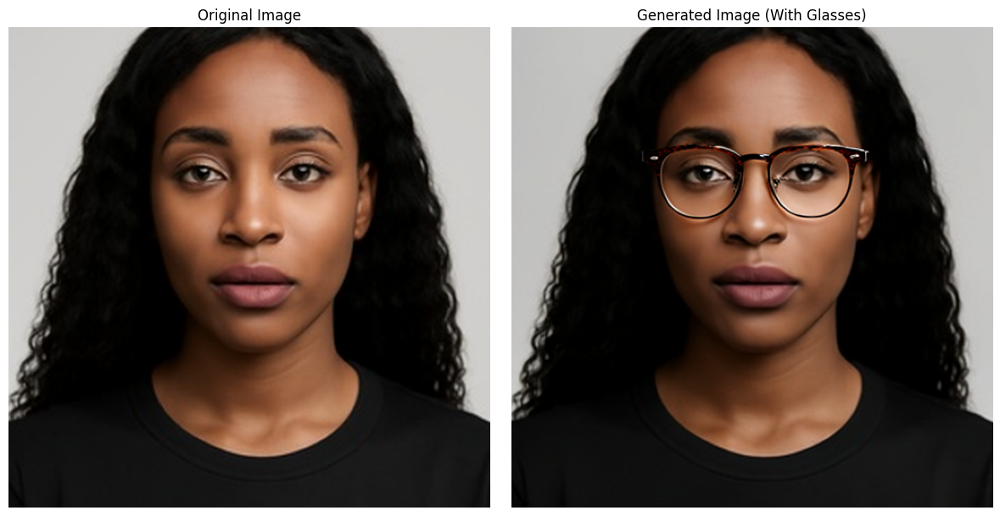

In [ ]:
import time
import glob
import os
import torch
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

# The prompt
PROMPT = "Add a classic reading glasses. don't change anything else"
TARGET_SIZE = 512
ACCESSORY_TYPE = "glasses"

# Pick the very first image
idx = 0
row = df.iloc[idx]
test_hash = row["HASH"]

# 1. Locate original image
matches = glob.glob(os.path.join(IMAGES_DIR, "**", f"{test_hash}*"), recursive=True)
if not matches:
    raise FileNotFoundError(f"Missing image for hash {test_hash}. Check if IMAGES_DIR is correct.")
source_path = matches[0]

# 2. Prepare image
original_image = Image.open(source_path).convert("RGB")
init_image = ImageOps.pad(
    original_image, (TARGET_SIZE, TARGET_SIZE),
    method=Image.LANCZOS, color=(255, 255, 255), centering=(0.5, 0.5)
)

logger.info(f"SMOKE TEST: Generating {ACCESSORY_TYPE} for {test_hash}...")
t0 = time.time()

# 3. Generate
result = pipe(
    image=init_image,
    prompt=PROMPT,
    guidance_scale=4.0,
    num_inference_steps=50,
    generator=torch.Generator(device="cuda").manual_seed(0),
).images[0]
elapsed = time.time() - t0

logger.info(f"Generated in {elapsed:.1f}s. Displaying without saving...")

# 4. Display Original and Result side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(init_image)
axes[0].set_title("Original Image")
axes[0].axis('off')

axes[1].imshow(result)
axes[1].set_title(f"Generated Image (With {ACCESSORY_TYPE.capitalize()})")
axes[1].axis('off')

plt.tight_layout()
plt.show()

Generation


In [ ]:
import time
import glob
import os
import torch
import pandas as pd
from PIL import Image, ImageOps

# The prompt
PROMPT = "Add a classic reading glasses. don't change anything else"
TARGET_SIZE = 512
ACCESSORY_TYPE = "glasses"

for idx in range(START_INDEX, len(df)):
    row = df.iloc[idx]
    test_hash = row["HASH"]

    # 1. Locate original image
    matches = glob.glob(os.path.join(IMAGES_DIR, "**", f"{test_hash}*"), recursive=True)
    if not matches:
        logger.warning(f"Missing image for hash {test_hash}. Skipping...")
        continue
    source_path = matches[0]

    # 2. Prepare image
    original_image = Image.open(source_path).convert("RGB")
    init_image = ImageOps.pad(
        original_image, (TARGET_SIZE, TARGET_SIZE),
        method=Image.LANCZOS, color=(255, 255, 255), centering=(0.5, 0.5)
    )

    logger.info(f"[{idx+1}/{len(df)}] Generating {ACCESSORY_TYPE} for {test_hash}...")
    t0 = time.time()

    # 3. Generate
    result = pipe(
        image=init_image,
        prompt=PROMPT,
        guidance_scale=4.0,
        num_inference_steps=50,
        generator=torch.Generator(device="cuda").manual_seed(0),
    ).images[0]
    elapsed = time.time() - t0

    # 4. Save Image (Format: hash_glasses.png)
    out_filename = f"{test_hash}_{ACCESSORY_TYPE}.png"
    out_filepath = os.path.join(OUTPUT_IMAGES_DIR, out_filename)
    result.save(out_filepath)

    # 5. Update CSV Tracker
    new_row = row.copy()
    new_row["ACCESSORY"] = ACCESSORY_TYPE
    pd.DataFrame([new_row]).to_csv(OUTPUT_CSV, mode='a', header=False, index=False)

    # 6. Update Checkpoint
    with open(CHECKPOINT_FILE, "w") as f:
        f.write(str(idx))

    logger.info(f"Saved {out_filename} in {elapsed:.1f}s")

logger.info("Generation run complete!")

2026-09-25 22:29:02,540 [INFO] [1/720] Generating glasses for 09534c3a20eaad55...


  0%|          | 0/50 [00:00<?, ?it/s]

2026-09-25 22:29:28,015 [INFO] Saved 09534c3a20eaad55_glasses.png in 25.2s
2026-09-25 22:29:32,867 [INFO] [2/720] Generating glasses for 2522757e41af90a0...


  0%|          | 0/50 [00:00<?, ?it/s]

2026-09-25 22:29:57,563 [INFO] Saved 2522757e41af90a0_glasses.png in 24.6s
2026-09-25 22:29:58,089 [INFO] [3/720] Generating glasses for be2c17990647d063...


...

2026-09-26 03:26:28,207 [INFO] Saved 7de85275e77b2d89_glasses.png in 23.6s
2026-09-26 03:26:28,745 [INFO] [719/720] Generating glasses for 2d17abef7513b47c...


  0%|          | 0/50 [00:00<?, ?it/s]

2026-09-26 03:26:52,495 [INFO] Saved 2d17abef7513b47c_glasses.png in 23.6s
2026-09-26 03:26:53,059 [INFO] [720/720] Generating glasses for a42b5980bbe630e5...


  0%|          | 0/50 [00:00<?, ?it/s]

2026-09-26 03:27:16,857 [INFO] Saved a42b5980bbe630e5_glasses.png in 23.7s
2026-09-26 03:27:16,858 [INFO] Generation run complete!
